<a href="https://colab.research.google.com/github/renzoespinoza-gif/Auditor-a-de-un-modelo-con-criterios-de-Gobierno-de-Datos-y-Cumplimiento-Normativo/blob/main/LABORATORIO_D13_AEI_PSAYAN_2026_02.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Analítica Empresarial Integrada — Laboratorio D13
## Semana 13 · Gobierno de Datos y Cumplimiento Normativo
**TECSUP 2026-II · Docente: Pilar Rocío Sayán Mejía**

### Auditoría de un modelo
**Sesgo por subgrupos + explicabilidad con SHAP + checklist de gobierno/cumplimiento**

Caso reproducible: **UCI Adult (ID 2)**.

> Las variables sensibles se usan para **auditoría**, no para recomendar decisiones discriminatorias.  
> SHAP explica el comportamiento del modelo; **no demuestra causalidad**.

## Identificación
- Nombre y apellidos: Renzo Espinoza Tuesta
- Sección: C28
- Enlace de mi Colab: https://colab.research.google.com/drive/1dkEKae1J5hqKP4uFAx8PayvmnJYg-Unr#scrollTo=ULl81q_CL6Lq
- Enlace de mi repositorio GitHub (carpeta semana13/):
- Uso de IA declarado: Claude como apoyo para resolver el laboratorio.

In [1]:
# Instala en Colab las librerías que no vienen por defecto (cliente de UCI, SHAP y Plotly)
%pip install -q ucimlrepo shap plotly

In [2]:
# Se silencian las advertencias de las librerías para leer mejor los resultados
import warnings
warnings.filterwarnings("ignore")
# pandas y numpy para los datos, Plotly y matplotlib para graficar
import numpy as np, pandas as pd
import plotly.express as px
import matplotlib.pyplot as plt
# ucimlrepo descarga el conjunto de datos desde UCI
from ucimlrepo import fetch_ucirepo
# scikit-learn: partición, preprocesamiento, modelo y métricas
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
# SHAP explica cuánto aporta cada variable a una predicción
import shap
# Permite ver hasta 100 columnas al imprimir tablas
pd.set_option("display.max_columns", 100)

# 1. Fuente, ficha y linaje

In [3]:
# UCI Adult (ID 2): variables de personas y si su ingreso supera 50 000 dólares al año
adult = fetch_ucirepo(id=2)
# X_raw son las variables; y_raw es la variable objetivo
X_raw = adult.data.features.copy()
y_raw = adult.data.targets.copy()

# Trazabilidad: nombre, identificador y dimensiones de la fuente
print("Dataset:", adult.metadata.name)
print("UCI ID: 2")
print("X:", X_raw.shape, "y:", y_raw.shape)
display(X_raw.head())
display(y_raw.head())

Dataset: Adult
UCI ID: 2
X: (48842, 14) y: (48842, 1)


,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba


,income
0,<=50K
1,<=50K
2,<=50K
3,<=50K
4,<=50K


In [4]:
# Limpia el texto: quita espacios y convierte los signos '?' en valores faltantes
def clean_str(s):
    s = s.astype("string").str.strip().replace({"?": pd.NA, "nan": pd.NA})
    return s.astype(object).where(s.notna(), np.nan)

# Se trabaja sobre una copia para conservar los datos originales
X = X_raw.copy()
for c in X.select_dtypes(include=["object","string"]).columns:
    X[c] = clean_str(X[c])

# Variable objetivo: 1 si el ingreso es mayor de 50K, 0 en caso contrario
target = y_raw.iloc[:,0].astype("string").str.strip().str.replace(".", "", regex=False)
y = target.str.contains(">50K", regex=False).astype(int)

# Proporción de cada clase: la clase positiva es minoritaria
print(y.value_counts(normalize=True).rename("proportion"))
# Calidad: cuántos valores faltantes tiene cada variable
print("Nulos por variable:")
display(X.isna().sum().sort_values(ascending=False).head(15))

income
0    0.760718
1    0.239282
Name: proportion, dtype: float64
Nulos por variable:


,0
occupation,2809
workclass,2799
native-country,857
education,0
fnlwgt,0
age,0
marital-status,0
education-num,0
race,0
relationship,0


### Ficha de gobierno
Complete:
- **Fuente:** UCI Machine Learning Repository, *Adult* (ID 2), 48 842 registros y 14 variables; extraído del censo de EE. UU. de 1994.
- **Finalidad académica:** practicar la auditoría de un modelo (sesgo por subgrupos, explicabilidad con SHAP y checklist de gobierno). No se usa para decidir sobre personas reales.
- **Variable objetivo:** `income` → 1 si el ingreso anual supera 50 000 USD (24 % de los casos), 0 en caso contrario.
- **Propietario/responsable propuesto:** docente del curso como dueña del dato; el estudiante como responsable del modelo y del notebook.
- **Variables sensibles usadas solo para auditoría:** `sex` y `race` (se retiran del entrenamiento y se conservan en la tabla `audit`).
- **Reglas de calidad:** `?` se trata como valor faltante; imputación con mediana (numéricas) y moda (categóricas); nulos solo en `occupation` (2 809), `workclass` (2 799) y `native-country` (857); la clase positiva se valida con proporción 24 % / 76 %.
- **Linaje:** fuente → limpieza → partición → transformación → modelo → predicción → auditoría.

### Pregunta 1
¿Qué información del origen y significado de los datos debería conocer un responsable antes de aprobar el uso del modelo?

**Respuesta:**

Antes de autorizar el uso de un modelo predictivo, el responsable debe conocer detalladamente la procedencia, las características y el significado de los datos utilizados para su desarrollo. En este caso, es necesario identificar que el conjunto de datos Adult proviene del repositorio UCI Machine Learning Repository y contiene información recopilada del censo de Estados Unidos de 1994. Esta antigüedad representa una limitación importante, ya que las condiciones socioeconómicas, laborales y demográficas pueden haber cambiado, por lo que los datos podrían no representar adecuadamente a la población actual ni a otros contextos geográficos.

Asimismo, debe comprender el significado de cada variable y su influencia dentro del análisis. Por ejemplo, `income` representa el nivel de ingresos anuales, clasificado según si supera o no los 50 000 dólares, mientras que `fnlwgt` corresponde a un factor de ponderación muestral y no a un ingreso económico individual. También es importante identificar las variables sensibles, como `race`, y aquellas que podrían actuar como indicadores indirectos de características personales.

Adicionalmente, el responsable debe verificar la finalidad para la cual fueron recopilados los datos, las condiciones de uso y licencia, la existencia de valores faltantes, los procedimientos de limpieza e imputación, las limitaciones de representatividad y los responsables de su administración.

---
En conclusión, conocer el origen y significado de los datos permite evaluar su confiabilidad, pertinencia y calidad, identificar posibles riesgos de sesgo y determinar si existe una justificación adecuada para utilizarlos. De esta manera, la aprobación del modelo se sustenta no solamente en su rendimiento predictivo, sino también en criterios de transparencia, trazabilidad, responsabilidad y uso adecuado de la información.


### Pregunta 2
¿Qué diferencia existe entre tener un archivo de datos y tener datos gobernados?

**Respuesta:**

La diferencia fundamental radica en que tener un archivo de datos significa disponer únicamente de un conjunto de registros almacenados, mientras que contar con datos gobernados implica disponer de información organizada, documentada y sometida a mecanismos de control y supervisión.

Un archivo de datos puede contener información sin que necesariamente se conozca quién la recopiló, cuál es su finalidad, qué significan sus variables, qué nivel de calidad presenta o quién es responsable de su administración.

Por el contrario, los datos gobernados cuentan con una estructura de responsabilidades claramente definida, que comprende la identificación de un propietario (Data Owner) y un responsable de su gestión (Data Steward), definiciones y metadatos, reglas de calidad verificables, trazabilidad de su origen y transformaciones (linaje), controles de acceso, así como la documentación de su finalidad y base legal para el tratamiento.

---
En conclusión, tener datos gobernados significa garantizar que la información no solamente esté disponible, sino que sea confiable, comprensible, trazable y utilizada bajo responsabilidades y controles definidos. Esto permite tomar decisiones analíticas con mayor transparencia, reducir riesgos y garantizar la rendición de cuentas durante todo el ciclo de vida de los datos.

# 2. Separación de variables sensibles para auditoría

In [5]:
# Busca una columna aunque cambie la forma de escribir su nombre
def find_col(cols, candidates):
    low={str(c).lower().replace("-","").replace("_","").replace(" ",""):c for c in cols}
    for x in candidates:
        k=x.lower().replace("-","").replace("_","").replace(" ","")
        if k in low: return low[k]
    return None

# Variables sensibles: se usan solo para auditar, no para entrenar
sex_col = find_col(X.columns, ["sex"])
race_col = find_col(X.columns, ["race"])
print("sex:", sex_col, "| race:", race_col)

# Tabla de auditoría con sexo y raza de cada persona
audit = pd.DataFrame(index=X.index)
audit["sex"] = X[sex_col].astype("string").fillna("Missing") if sex_col else "Unavailable"
audit["race"] = X[race_col].astype("string").fillna("Missing") if race_col else "Unavailable"

# Se retiran las variables sensibles de las que entrenan el modelo
drop_sensitive = [c for c in [sex_col, race_col] if c is not None]
X_model = X.drop(columns=drop_sensitive).copy()
# Número de variables que ve el modelo
print("Variables del modelo:", X_model.shape[1])

sex: sex | race: race
Variables del modelo: 12


### Pregunta 3
¿Por qué excluir una variable sensible del entrenamiento no garantiza por sí solo ausencia de sesgo?

**Respuesta:**

Excluir una variable sensible del entrenamiento, como `sex` (sexo) o `race` (raza), no garantiza por sí solo la ausencia de sesgo, debido a que otras variables del conjunto de datos pueden estar relacionadas directa o indirectamente con dichas características. Estas variables, conocidas como variables proxy, pueden transmitir patrones de desigualdad incluso cuando la característica sensible no se utiliza explícitamente para entrenar el modelo.

Por ello, como analista de datos, es necesario evaluar las variables proxy, analizar las métricas de desempeño por subgrupos y realizar auditorías de equidad. La ausencia de variables sensibles en el entrenamiento no equivale a la ausencia de sesgo; este debe identificarse y evaluarse mediante controles específicos durante el desarrollo y la validación del modelo.

# 3. Train/test y modelo base

In [6]:
# Partición 75 % / 25 % estratificada por la variable objetivo; la semilla fija repite el resultado
idx_train, idx_test = train_test_split(
    X_model.index, test_size=0.25, random_state=42, stratify=y
)
# Se separan variables y objetivo de entrenamiento y de prueba
X_train, X_test = X_model.loc[idx_train], X_model.loc[idx_test]
y_train, y_test = y.loc[idx_train], y.loc[idx_test]
# La auditoría usa solo las personas de la muestra de prueba
audit_test = audit.loc[idx_test].copy()

# Variables numéricas y categóricas se tratan por separado
num_cols = X_model.select_dtypes(include=np.number).columns.tolist()
cat_cols = [c for c in X_model.columns if c not in num_cols]

# Numéricas: se completan con la mediana y se estandarizan
num_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scale", StandardScaler())
])
# Categóricas: se completan con la moda y se codifican en columnas 0/1
cat_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])
# Preprocesamiento único para ambos tipos de variables
prep = ColumnTransformer([
    ("num", num_pipe, num_cols),
    ("cat", cat_pipe, cat_cols)
], verbose_feature_names_out=False)

# Regresión logística con pesos balanceados para compensar la clase minoritaria
pipe = Pipeline([
    ("prep", prep),
    ("model", LogisticRegression(max_iter=1500, class_weight="balanced", random_state=42))
])

# El modelo se ajusta solo con la muestra de entrenamiento
pipe.fit(X_train, y_train)
# Probabilidad estimada de ingreso mayor de 50K
proba = pipe.predict_proba(X_test)[:,1]
# Predicción con umbral de 0,50
pred = (proba >= 0.50).astype(int)

# Métricas globales sobre la muestra de prueba
global_metrics = pd.DataFrame([{
    "accuracy": accuracy_score(y_test,pred),
    "precision": precision_score(y_test,pred,zero_division=0),
    "recall": recall_score(y_test,pred,zero_division=0),
    "f1": f1_score(y_test,pred,zero_division=0)
}])
display(global_metrics.round(4))

,accuracy,precision,recall,f1
0,0.8012,0.5566,0.8323,0.6671


# 4. Auditoría por subgrupos

In [7]:
# Se une la auditoría con el valor real, la predicción y la probabilidad
audit_result = audit_test.copy()
audit_result["y_true"] = y_test
audit_result["y_pred"] = pred
audit_result["proba"] = proba

# Métricas por subgrupo; se omiten grupos de menos de 100 personas
def group_metrics(df, group_col, min_n=100):
    rows=[]
    for g,d in df.groupby(group_col, dropna=False):
        if len(d) < min_n:
            continue
        # Matriz de confusión del grupo: verdaderos y falsos, positivos y negativos
        tn,fp,fn,tp = confusion_matrix(d.y_true,d.y_pred,labels=[0,1]).ravel()
        rows.append({
            "dimension":group_col,
            "group":str(g),
            "n":len(d),
            "positive_rate_pred":d.y_pred.mean(),
            "accuracy":accuracy_score(d.y_true,d.y_pred),
            "recall":recall_score(d.y_true,d.y_pred,zero_division=0),
            "fpr":fp/(fp+tn) if (fp+tn)>0 else np.nan,
            "fnr":fn/(fn+tp) if (fn+tp)>0 else np.nan
        })
    return pd.DataFrame(rows)

# Auditoría por sexo y por raza
gm_sex = group_metrics(audit_result,"sex")
gm_race = group_metrics(audit_result,"race")
# Tabla única con todos los subgrupos
group_table = pd.concat([gm_sex,gm_race],ignore_index=True)
display(group_table.round(4))

,dimension,group,n,positive_rate_pred,accuracy,recall,fpr,fnr
0,sex,Female,4057,0.1541,0.8925,0.7086,0.0844,0.2914
1,sex,Male,8154,0.4592,0.7558,0.8550,0.2872,0.1450
2,race,Amer-Indian-Eskimo,126,0.2698,0.7857,0.8182,0.2174,0.1818
3,race,Asian-Pac-Islander,369,0.3821,0.7751,0.8021,0.2344,0.1979
4,race,Black,1186,0.1804,0.8769,0.7361,0.1036,0.2639
5,race,White,10442,0.3795,0.7932,0.8391,0.2224,0.1609


In [8]:
# Un gráfico de barras por dimensión: recall, tasa de falsos positivos y de falsos negativos
for dim in ["sex","race"]:
    d=group_table[group_table.dimension==dim]
    if len(d):
        fig=px.bar(d,x="group",y=["recall","fpr","fnr"],barmode="group",
                   title=f"Auditoría por subgrupo — {dim}")
        fig.show()

### Pregunta 4
¿Qué métrica global podría ocultar una diferencia importante entre grupos?

**Respuesta:**

La exactitud global (accuracy = 0,80) puede ocultar diferencias importantes en el desempeño del modelo entre distintos grupos. Aunque el resultado general parece aceptable, la exactitud es de 0,89 en mujeres y 0,76 en hombres. Además, las mujeres presentan una tasa de falsos negativos (FNR) de 0,29, frente a 0,15 en hombres, lo que significa que el modelo no identifica correctamente una mayor proporción de mujeres que realmente pertenecen a la clase de ingresos superiores a 50 000 dólares.

Por tanto, la accuracy global no permite identificar por sí sola cómo se distribuyen los errores entre los grupos. Es necesario complementarla con métricas desagregadas, como recall, FNR y FPR, para detectar posibles diferencias de equidad.

### Pregunta 5
¿Qué brecha observada merece primero una revisión empresarial? Sustente con magnitud, tamaño de grupo y tipo de error.

**Respuesta:**

La brecha que merece una primera revisión empresarial es la identificada por sexo, debido a su magnitud y a que afecta a grupos numerosos de la muestra. La tasa positiva de predicción es de 0,46 en hombres y 0,15 en mujeres, lo que representa una diferencia de 30,5 puntos porcentuales.

En cuanto al tamaño de los grupos evaluados, se identificaron 4 057 mujeres y 8 154 hombres. El principal problema se encuentra en la tasa de falsos negativos (FNR): el modelo no identifica el 29,1 % de las mujeres que realmente tienen ingresos superiores a 50 000 dólares, frente al 14,5 % de los hombres. Esto representa una brecha de 14,6 puntos porcentuales, perjudicando especialmente a las mujeres.

Adicionalmente, los hombres presentan una mayor tasa de falsos positivos (FPR: 0,29 frente a 0,08 en mujeres), lo que evidencia que los errores también se distribuyen de manera desigual entre ambos grupos.

En consecuencia, recomendaría priorizar una revisión de las variables utilizadas, los posibles proxies del sexo (relationship y marital-status) y el umbral de decisión, con el propósito de reducir las diferencias identificadas y evitar decisiones empresariales discriminatorias.

# 5. Brechas cuantificadas

In [9]:
# Brecha = valor más alto menos valor más bajo de una métrica entre subgrupos
def gap_report(tbl, metric):
    x=tbl.dropna(subset=[metric]).copy()
    if len(x)<2: return None
    hi=x.loc[x[metric].idxmax()]
    lo=x.loc[x[metric].idxmin()]
    return {
        "metric":metric,
        "max_group":hi["group"], "max_value":hi[metric],
        "min_group":lo["group"], "min_value":lo[metric],
        "gap":hi[metric]-lo[metric]
    }

# Se calcula la brecha de cuatro métricas en cada dimensión
gaps=[]
for dim in ["sex","race"]:
    t=group_table[group_table.dimension==dim]
    for metric in ["positive_rate_pred","recall","fpr","fnr"]:
        r=gap_report(t,metric)
        if r: r["dimension"]=dim; gaps.append(r)
# Tabla de brechas, de mayor a menor
gap_df=pd.DataFrame(gaps)
display(gap_df.sort_values("gap",ascending=False).round(4))

,metric,max_group,max_value,min_group,min_value,gap,dimension
0,positive_rate_pred,Male,0.4592,Female,0.1541,0.3051,sex
2,fpr,Male,0.2872,Female,0.0844,0.2029,sex
4,positive_rate_pred,Asian-Pac-Islander,0.3821,Black,0.1804,0.2017,race
1,recall,Male,0.8550,Female,0.7086,0.1464,sex
3,fnr,Female,0.2914,Male,0.1450,0.1464,sex
6,fpr,Asian-Pac-Islander,0.2344,Black,0.1036,0.1308,race
7,fnr,Black,0.2639,White,0.1609,0.1030,race
5,recall,White,0.8391,Black,0.7361,0.1030,race


# 6. Explicabilidad con SHAP

Muestra SHAP: (500, 98)


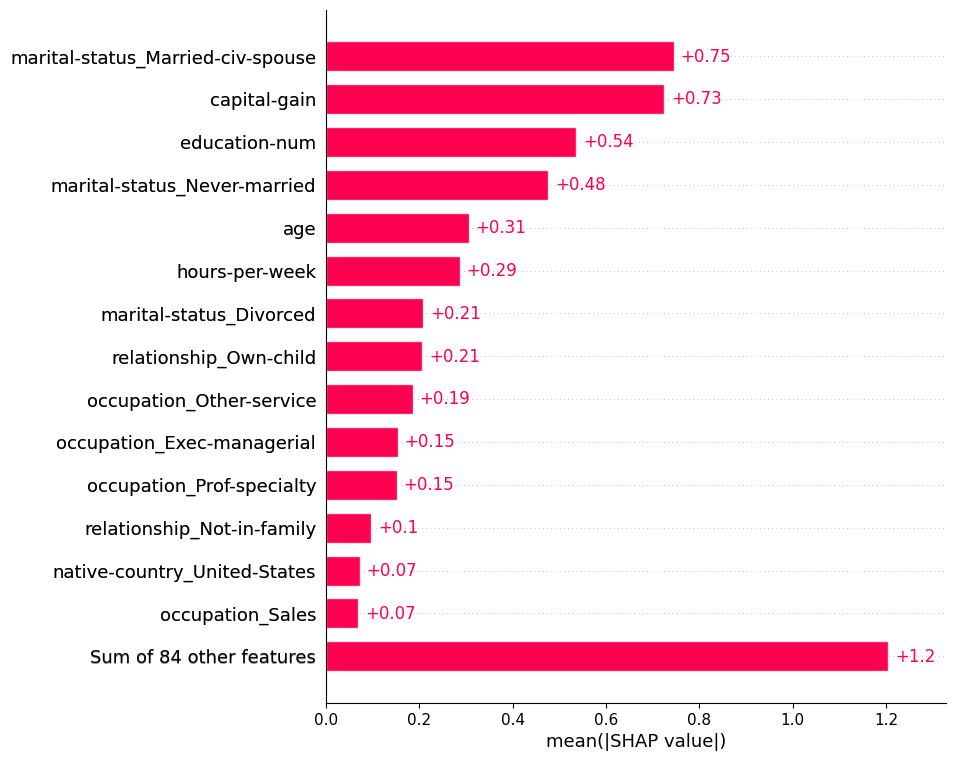

In [10]:
# Se recuperan el preprocesamiento y el modelo ya entrenados
transformer = pipe.named_steps["prep"]
model = pipe.named_steps["model"]

# Datos transformados: es lo que realmente ve el modelo
X_train_t = transformer.transform(X_train)
X_test_t = transformer.transform(X_test)
# Nombres de las columnas transformadas
feature_names = transformer.get_feature_names_out()

# Se explica una muestra de 500 personas de la prueba para que sea rápido
# Generador con semilla fija para repetir la muestra
rng = np.random.default_rng(42)
sample_n = min(500, X_test_t.shape[0])
sample_pos = rng.choice(X_test_t.shape[0], size=sample_n, replace=False)
X_shap = X_test_t[sample_pos]

# Explicador SHAP para modelos lineales
explainer = shap.LinearExplainer(model, X_train_t)
shap_values = explainer(X_shap)
# Se asignan los nombres de las columnas transformadas para que los gráficos sean legibles
shap_values.feature_names = list(feature_names)

print("Muestra SHAP:", X_shap.shape)
# Importancia global: promedio del aporte absoluto de cada variable
shap.plots.bar(shap_values, max_display=15)

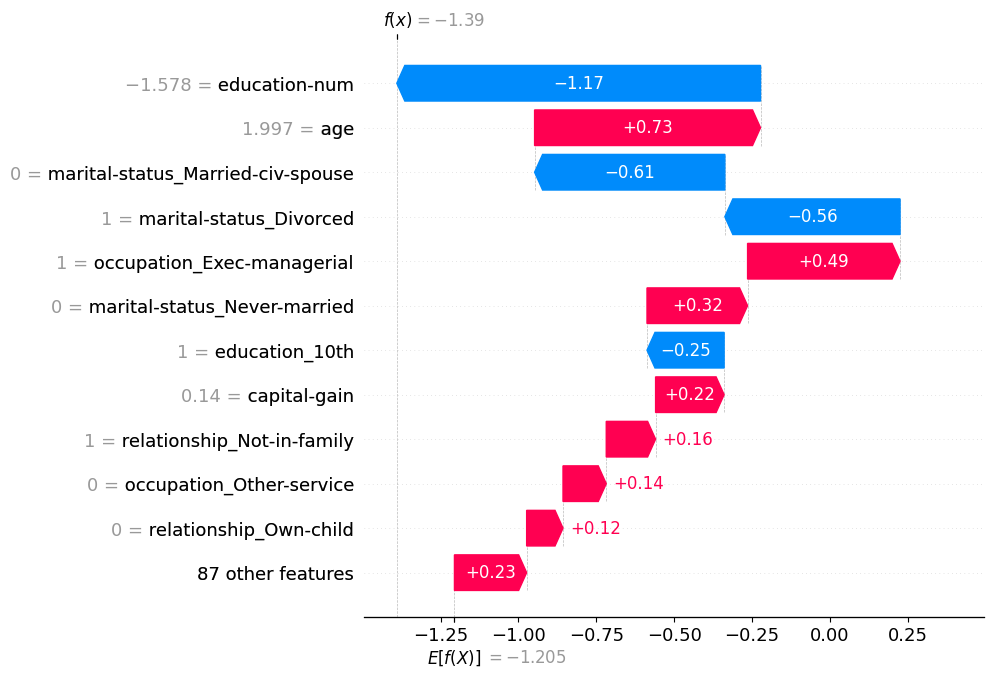

In [11]:
# Explicación local: cómo cada variable empuja la probabilidad de un caso concreto
case = 0
# Gráfico en cascada del primer caso de la muestra
shap.plots.waterfall(shap_values[case], max_display=12)

### Pregunta 6
¿Cuáles variables tienen mayor influencia global en las predicciones?

**Respuesta:** `

Según el análisis de importancia global mediante SHAP, las variables con mayor aporte medio absoluto son `marital-status_Married-civ-spouse` (0,75), `capital-gain` (0,73) y `education-num` (0,54). Les siguen `marital-status_Never-married` (0,48), `age` (0,31) y `hours-per-week` (0,29). Al agrupar las categorías de las variables originales, `marital-status` representa el mayor aporte global, con un 28,9 %. Estos resultados reflejan la influencia de las variables en las predicciones del modelo, no relaciones causales.

### Pregunta 7
Elija una predicción y explique qué variables aumentaron o redujeron la probabilidad estimada. No use lenguaje causal.

**Respuesta:**

Para el caso 0, correspondiente a un hombre con predicción negativa (ingreso igual o inferior a 50 000 USD), el modelo estimó una probabilidad aproximada de 0,20, frente a un valor base de 0,23. Entre las variables asociadas con un incremento de la predicción destacan la edad alta (+0,73 en log-odds), la ocupación `Exec-managerial` (+0,49) y no pertenecer a la categoría `Never-married` (+0,32). Por otro lado, los pocos años de educación (−1,17), no estar casado civilmente (−0,61) y pertenecer a la categoría `Divorced` (−0,56) presentan aportes negativos. Estos valores representan contribuciones de las variables a la predicción del modelo y no efectos causales.

# 7. Checklist académico de gobierno y cumplimiento

In [12]:
# Checklist académico de gobierno: cada control tiene un estado inicial por completar
checklist = pd.DataFrame([
    ["Finalidad","¿Está documentado para qué se usará el modelo?","No evidenciado","La ficha de gobierno declara finalidad académica; falta aprobación formal."],
    ["Minimización","¿Cada variable tiene una justificación de necesidad?","No evidenciado","sex y race se excluyen del entrenamiento; no hay justificación por variable (ver Ejercicio 1)."],
    ["Calidad","¿Hay reglas y resultados de calidad de datos?","Parcial","El notebook muestra nulos y limpieza."],
    ["Linaje","¿Puede seguirse fuente→transformación→modelo→salida?","Parcial","Pipeline reproducible en notebook."],
    ["Acceso","¿Están definidos roles y permisos sobre datos/modelo?","No evidenciado","No hay roles ni permisos documentados."],
    ["Transparencia","¿Se documentan lógica, limitaciones y supervisión?","Parcial","Completar informe ejecutivo."],
    ["Auditoría de subgrupos","¿Se revisaron errores y tasas por grupos?","Cumple","Ver tabla de auditoría."],
    ["Supervisión humana","¿Existe responsable para revisar decisiones de alto impacto?","No evidenciado","No hay responsable de supervisión designado."],
], columns=["control","pregunta","estado_inicial","evidencia"])
display(checklist)

,control,pregunta,estado_inicial,evidencia
0,Finalidad,¿Está documentado para qué se usará el modelo?,No evidenciado,La ficha de gobierno declara finalidad académi...
1,Minimización,¿Cada variable tiene una justificación de nece...,No evidenciado,sex y race se excluyen del entrenamiento; no h...
2,Calidad,¿Hay reglas y resultados de calidad de datos?,Parcial,El notebook muestra nulos y limpieza.
3,Linaje,¿Puede seguirse fuente→transformación→modelo→s...,Parcial,Pipeline reproducible en notebook.
4,Acceso,¿Están definidos roles y permisos sobre datos/...,No evidenciado,No hay roles ni permisos documentados.
5,Transparencia,"¿Se documentan lógica, limitaciones y supervis...",Parcial,Completar informe ejecutivo.
6,Auditoría de subgrupos,¿Se revisaron errores y tasas por grupos?,Cumple,Ver tabla de auditoría.
7,Supervisión humana,¿Existe responsable para revisar decisiones de...,No evidenciado,No hay responsable de supervisión designado.


Edite el checklist con uno de estos estados:

- **Cumple**
- **Parcial**
- **No evidenciado**
- **No aplica**

> Este checklist es **académico**. No constituye certificación legal.

### Pregunta 8
¿Qué control no puede demostrarse solo con código y necesita evidencia organizacional adicional?

**Respuesta:**

El control de supervisión humana no puede acreditarse únicamente mediante código, ya que requiere demostrar que existe una persona formalmente designada para revisar los resultados del modelo, evaluar posibles errores y adoptar medidas correctivas cuando se identifiquen riesgos. Para acreditar este control se necesita evidencia organizacional, como una designación formal del responsable, políticas de supervisión, procedimientos de revisión y actas de aprobación.

Asimismo, el control de acceso a los datos requiere documentación adicional, como una matriz de roles y permisos, políticas de seguridad y registros de acceso. Por tanto, ambos controles necesitan evidencias institucionales que complementen la implementación técnica.

# 8. Registro de hallazgos y plan de acción

In [13]:
# Registro de hallazgos: severidad, evidencia, acción, responsable y estado
hallazgos = pd.DataFrame(columns=[
    "hallazgo","severidad","evidencia","accion","responsable","estado"
])
filas = [
    ["Brecha por sexo: FNR 0,29 en mujeres frente a 0,15 en hombres; FPR 0,08 frente a 0,29",
     "Alta", "gm_sex / gap_df (tasa positiva 0,15 vs 0,46)",
     "Revisar datos, umbral, variables proxy y proceso de supervisión; repetir la auditoría tras la mitigación",
     "Owner del modelo + negocio", "Abierto"],
    ["Variables proxy del sexo (relationship, marital-status) siguen en el modelo",
     "Alta", "Ejercicio 1: Husband 100 % hombres, Wife 99,9 % mujeres, Married-civ-spouse 88,9 % hombres",
     "Evaluar retirar o transformar las variables y medir el efecto en desempeño y brechas",
     "Equipo de datos", "Abierto"],
    ["Ningún umbral elimina a la vez las brechas de FNR y FPR por sexo",
     "Media", "Ejercicio 2 (umbrales 0,30, 0,50 y 0,70)",
     "El comité de gobierno decide el umbral según el costo de cada tipo de error",
     "Comité de gobierno + negocio", "Abierto"],
    ["Brecha por raza: FNR 0,26 en Black frente a 0,16 en White; grupo Amer-Indian muy pequeño (n=126)",
     "Media", "gm_race / gap_df",
     "Monitorear la brecha y reunir más datos de los grupos pequeños antes de concluir",
     "Equipo de datos", "Abierto"],
    ["Brecha por edad: FNR 0,29 en 17-29 años frente a 0,13 en 50+",
     "Media", "Ejercicio 3 (n=3 663 en 17-29)",
     "Analizar si el modelo excluye sistemáticamente a clientes jóvenes",
     "Owner del modelo", "Abierto"],
    ["Sin roles de acceso ni responsable de supervisión humana documentados",
     "Alta", "Checklist: Acceso y Supervisión humana = No evidenciado",
     "Designar responsable, definir matriz de roles/permisos y procedimiento de revisión",
     "Gobierno de datos / Dirección", "Abierto"],
]
for i, f in enumerate(filas):
    hallazgos.loc[i] = f
display(hallazgos)

,hallazgo,severidad,evidencia,accion,responsable,estado
0,"Brecha por sexo: FNR 0,29 en mujeres frente a ...",Alta,"gm_sex / gap_df (tasa positiva 0,15 vs 0,46)","Revisar datos, umbral, variables proxy y proce...",Owner del modelo + negocio,Abierto
1,"Variables proxy del sexo (relationship, marita...",Alta,"Ejercicio 1: Husband 100 % hombres, Wife 99,9 ...",Evaluar retirar o transformar las variables y ...,Equipo de datos,Abierto
2,Ningún umbral elimina a la vez las brechas de ...,Media,"Ejercicio 2 (umbrales 0,30, 0,50 y 0,70)",El comité de gobierno decide el umbral según e...,Comité de gobierno + negocio,Abierto
3,"Brecha por raza: FNR 0,26 en Black frente a 0,...",Media,gm_race / gap_df,Monitorear la brecha y reunir más datos de los...,Equipo de datos,Abierto
4,"Brecha por edad: FNR 0,29 en 17-29 años frente...",Media,Ejercicio 3 (n=3 663 en 17-29),Analizar si el modelo excluye sistemáticamente...,Owner del modelo,Abierto
5,Sin roles de acceso ni responsable de supervis...,Alta,Checklist: Acceso y Supervisión humana = No ev...,"Designar responsable, definir matriz de roles/...",Gobierno de datos / Dirección,Abierto


### Pregunta 9
¿Qué hallazgo impediría desplegar el modelo hasta ser resuelto?

**Respuesta:**

El principal hallazgo que impediría desplegar el modelo para tomar decisiones sobre personas es la existencia de brechas significativas de desempeño entre grupos, especialmente las diferencias identificadas por sexo en las tasas de falsos negativos (FNR): 0,29 en mujeres frente a 0,15 en hombres.

Esta diferencia evidencia que el modelo presenta un mayor porcentaje de errores al identificar a mujeres que realmente pertenecen a la categoría de ingresos superiores a 50 000 USD. Además, se identificaron diferencias en las tasas de falsos positivos y posibles variables proxy relacionadas con el sexo.

Por ello, antes de autorizar su implementación, sería necesario investigar las causas de estas diferencias, evaluar medidas de mitigación, validar nuevamente el modelo y obtener la aprobación correspondiente del comité de gobierno de datos. Mientras estas brechas no sean evaluadas y gestionadas, no recomendaría su despliegue para decisiones que afecten a personas.

---

La brecha por sexo (FNR 0,29 frente a 0,15 y tasa positiva 0,15 frente a 0,46) sin mitigación ni explicación, junto con los proxies del sexo que siguen en el modelo y la falta de supervisión humana. Hasta resolverlos no se desplegaría para decidir sobre personas.

### Pregunta 10
¿Qué evidencia conservaría para demostrar que el modelo fue auditado y revisado antes de su uso?

**Respuesta:**

Conservaría un expediente de auditoría que permita demostrar la trazabilidad del desarrollo, evaluación y aprobación del modelo. Este expediente debería incluir:

1. Documentación de los datos: fuente del conjunto de datos, versión utilizada, fecha de obtención, diccionario de variables y procedimientos de limpieza y transformación.
2. Evidencia técnica: notebook ejecutado, código versionado, configuración del modelo, semilla aleatoria y versiones de las librerías utilizadas.
3. Resultados de evaluación: métricas globales y desagregadas por sexo, raza y edad, incluyendo accuracy, FNR, FPR y tasas de predicción positiva.
4. Explicabilidad: gráficos de importancia global SHAP y explicaciones individuales de las predicciones analizadas.
5. Registro de hallazgos: identificación de brechas, riesgos detectados, medidas correctivas propuestas, responsables y fechas de seguimiento.
6. Evidencia organizacional: actas de revisión del comité, aprobación de la finalidad, designación de responsables y documentación de los controles de acceso y supervisión humana.

En conclusión, conservaría tanto la evidencia técnica como la documental y organizacional, de manera que cualquier revisión posterior permita verificar qué datos se utilizaron, cómo se comportó el modelo, qué riesgos se identificaron y quién autorizó su utilización.

Conservaría: el notebook versionado con semilla y versiones de librerías, la versión y fuente del dataset, las tablas `group_table` y `gap_df` exportadas, los gráficos SHAP, el checklist y el registro de hallazgos con fechas y responsables, y el acta de revisión y aprobación del comité.

# 9. Informe ejecutivo de auditoría
Responda en términos de negocio, con las cifras del notebook (máximo 12 líneas en total).

**A. Describa el desempeño global del modelo y dos métricas por subgrupo que matizan ese resultado.**

**Respuesta:**

El modelo clasifica bien en conjunto (accuracy 0,80, recall 0,83, precisión 0,56, F1 0,67), pero el recall baja a 0,71 en mujeres (0,86 en hombres) y la tasa positiva predicha es 0,15 frente a 0,46.

**B. Identifique la principal brecha, indique el tamaño de los grupos involucrados y el tipo de error.**

**Respuesta:**

La mayor brecha es por sexo: tasa positiva de 30,5 pp y FNR de 0,29 en mujeres (n=4 057) frente a 0,15 en hombres (n=8 154), es decir, más falsos negativos para ellas; los falsos positivos se concentran en hombres (FPR 0,29 frente a 0,08).

**C. Presente una explicación SHAP global y una local, sin lenguaje causal.**

**Respuesta:**

SHAP global: `marital-status_Married-civ-spouse`, `capital-gain` y `education-num` tienen el mayor aporte medio; agregada por variable, `marital-status` lidera (28,9 %). SHAP local (caso 0): probabilidad ≈0,20; edad alta y ocupación ejecutiva se asocian con una probabilidad mayor, y pocos años de educación y no estar casado civil con una menor (sin lenguaje causal).

**D. Señale dos controles de gobierno revisados y una evidencia de cumplimiento faltante.**

**Respuesta:**

Revisados: auditoría de subgrupos (Cumple) y linaje (Parcial). Falta evidencia organizacional de supervisión humana y de roles y permisos de acceso.

**E. Indique una limitación y su recomendación: aprobar, aprobar con condiciones o no aprobar todavía.**

**Respuesta:**

Limitación: datos de 1994 con proxies del sexo en el modelo y brechas sin mitigar. Recomendación: **no aprobar todavía** para decidir sobre personas; reevaluar tras mitigar y designar un responsable de supervisión.

# 10. Reto de aplicación y retroalimentación
Los cinco ejercicios operan sobre `X_model`, `audit`, `audit_result`, `proba`, `shap_values` y `checklist`. Cada respuesta escrita no debe exceder cuatro líneas.

In [14]:
# Objetos de trabajo para la sección de retos.
print("Variables del modelo:", X_model.shape)
print("Auditoría de prueba:", audit_result.shape)
print("Valores SHAP:", shap_values.values.shape)

Variables del modelo: (48842, 12)
Auditoría de prueba: (12211, 5)
Valores SHAP: (500, 98)


## Ejercicio 1 — Detección de variables proxy del sexo
En el Paso 3 se excluyó la variable sex del entrenamiento. Sin embargo, una exclusión solo es efectiva si ninguna otra variable reproduce la información retirada. En este ejercicio deberá comprobar numéricamente si relationship y marital-status, que el modelo sí recibe, permiten reconstruir el sexo de las personas.

**Se solicita:**
- Construir una tabla cruzada entre relationship y el sexo de la tabla de auditoría, normalizada por fila.
- Construir la misma tabla para marital-status.
- Identificar las categorías en que un solo sexo supera el 85 % de los casos.

In [15]:
# Ejercicio 1: ¿relationship y marital-status reconstruyen el sexo?
for var in ["relationship", "marital-status"]:
    categoria = X_model[var].fillna("Missing")
    tabla = pd.crosstab(categoria, audit["sex"], normalize="index")   # % por fila
    sexos = list(tabla.columns)
    tabla["n"] = categoria.value_counts()
    print(f"\n{var}: proporción de cada sexo dentro de cada categoría")
    display(tabla.round(3))
    proxy = tabla[tabla[sexos].max(axis=1) > 0.85]
    print("Categorías donde un solo sexo supera el 85 %:", proxy.index.tolist())


relationship: proporción de cada sexo dentro de cada categoría


sex,Female,Male,n
relationship,,,
Husband,0.000,1.000,19716
Not-in-family,0.467,0.533,12583
Other-relative,0.458,0.542,1506
Own-child,0.445,0.555,7581
Unmarried,0.766,0.234,5125
Wife,0.999,0.001,2331


Categorías donde un solo sexo supera el 85 %: ['Husband', 'Wife']

marital-status: proporción de cada sexo dentro de cada categoría


sex,Female,Male,n
marital-status,,,
Divorced,0.603,0.397,6633
Married-AF-spouse,0.676,0.324,37
Married-civ-spouse,0.111,0.889,22379
Married-spouse-absent,0.484,0.516,628
Never-married,0.448,0.552,16117
Separated,0.608,0.392,1530
Widowed,0.812,0.188,1518


Categorías donde un solo sexo supera el 85 %: ['Married-civ-spouse']


**Pregunta 11.**

¿Qué variable funciona como proxy más fuerte del sexo y qué implica para la decisión de excluir sex del modelo?

**Respuesta:**

La variable que presenta una relación más evidente con el sexo es relationship, especialmente a través de sus categorías Husband y Wife. En el conjunto de datos, la categoría Husband está conformada prácticamente en su totalidad por hombres (100 %), mientras que Wife corresponde casi exclusivamente a mujeres (99,9 %).

Este hallazgo demuestra que, aunque la variable sex se excluya directamente del entrenamiento, otras variables pueden contener información estrechamente relacionada con esta característica sensible. Por tanto, su exclusión no garantiza que el modelo deje de reproducir diferencias entre hombres y mujeres.

Desde la perspectiva del gobierno de datos, se debe evaluar si mantener estas variables resulta justificable para la finalidad del modelo y analizar su influencia sobre las predicciones. No se debe asumir que eliminar sex es suficiente para garantizar la ausencia de sesgo.

## Ejercicio 2 — Efecto del umbral de decisión sobre las brechas
El modelo base clasifica como positivo a quien supera una probabilidad de 0,50. Ese umbral no es un dato técnico neutral, sino una decisión de negocio que redistribuye los errores entre los grupos. Corresponde medir cómo cambian las brechas por sexo al mover el umbral.

**Se solicita:**
- Recalcular las predicciones con umbrales de 0,30, 0,50 y 0,70.
- Obtener, para cada umbral, el FNR y el FPR de mujeres y de hombres con la función group_metrics.
- Construir las columnas brecha_fnr y brecha_fpr y presentar los resultados en una tabla.

In [16]:
# Ejercicio 2: efecto del umbral sobre las brechas por sexo
resultados = []
for t in [0.30, 0.50, 0.70]:
    tmp = audit_result.copy()
    tmp["y_pred"] = (tmp["proba"] >= t).astype(int)     # nuevo umbral de decisión
    g = group_metrics(tmp, "sex").set_index("group")
    resultados.append({
        "umbral": t,
        "fnr_mujeres": g.loc["Female", "fnr"], "fnr_hombres": g.loc["Male", "fnr"],
        "fpr_mujeres": g.loc["Female", "fpr"], "fpr_hombres": g.loc["Male", "fpr"],
    })
umbrales = pd.DataFrame(resultados)
# Brecha = diferencia absoluta entre mujeres y hombres
umbrales["brecha_fnr"] = (umbrales["fnr_mujeres"] - umbrales["fnr_hombres"]).abs()
umbrales["brecha_fpr"] = (umbrales["fpr_mujeres"] - umbrales["fpr_hombres"]).abs()
display(umbrales.round(4))

,umbral,fnr_mujeres,fnr_hombres,fpr_mujeres,fpr_hombres,brecha_fnr,brecha_fpr
0,0.3,0.1545,0.0502,0.1615,0.4355,0.1043,0.2740
1,0.5,0.2914,0.1450,0.0844,0.2872,0.1464,0.2029
2,0.7,0.4371,0.3196,0.0366,0.1321,0.1175,0.0955


**Pregunta 12.** ¿Existe un umbral que elimine a la vez las brechas de FNR y de FPR? ¿Quién debería decidir el umbral final?

**Respuesta:**

No. De acuerdo con los resultados del laboratorio, no se identificó un umbral de clasificación que permita eliminar simultáneamente las brechas de las tasas de falsos negativos (FNR) y falsos positivos (FPR) entre los grupos evaluados.

Esto significa que modificar el umbral puede mejorar una métrica de equidad, pero también puede incrementar la diferencia en otra. Por ello, no sería adecuado seleccionar un umbral únicamente con criterios técnicos o buscando maximizar la exactitud del modelo.

La decisión final debería corresponder a un comité de gobierno de datos, con participación de las áreas de negocio, cumplimiento normativo y responsables del modelo. Este comité debe evaluar las consecuencias de los errores, los riesgos de discriminación, la finalidad del sistema y los requisitos legales aplicables. El analista de datos debe proporcionar la evidencia técnica y las alternativas disponibles, pero no tomar unilateralmente la decisión.

No. Al subir el umbral la brecha de FPR baja (0,274 → 0,203 → 0,096), pero la de FNR se mueve poco (0,104, 0,146, 0,118) y ninguna llega a cero; el umbral solo redistribuye los errores. Debe fijarlo un comité de gobierno con negocio y cumplimiento, según el costo de cada tipo de error, no el analista.

## Ejercicio 3 — Nueva dimensión de auditoría: grupos de edad
La auditoría de la Actividad 2 se limitó al sexo y a la raza. Un comité de gobierno, sin embargo, suele pedir otras dimensiones de riesgo. La edad es una de ellas: un modelo puede dejar sistemáticamente fuera a los clientes jóvenes, aun cuando la variable age forme parte legítima del modelo.

**Se solicita:**
- Crear la columna grupo_edad en audit_result con los tramos 17-29, 30-49 y 50+.
- Aplicar group_metrics a la nueva dimensión.
- Calcular con gap_report la brecha de FNR y la de tasa positiva predicha.

In [17]:
# Ejercicio 3: nueva dimensión de auditoría, grupos de edad
audit_result["grupo_edad"] = pd.cut(
    X_model.loc[audit_result.index, "age"],
    bins=[16, 29, 49, 200], labels=["17-29", "30-49", "50+"]
)
gm_edad = group_metrics(audit_result, "grupo_edad")
display(gm_edad.round(4))
# Brecha de FNR y de tasa positiva predicha entre grupos de edad
for m in ["fnr", "positive_rate_pred"]:
    display(pd.DataFrame([gap_report(gm_edad, m)]).round(4))

,dimension,group,n,positive_rate_pred,accuracy,recall,fpr,fnr
0,grupo_edad,17-29,3663,0.0975,0.9233,0.7135,0.0660,0.2865
1,grupo_edad,30-49,5868,0.4385,0.7682,0.8266,0.2588,0.1734
2,grupo_edad,50+,2680,0.5369,0.7067,0.8681,0.3731,0.1319


,metric,max_group,max_value,min_group,min_value,gap
0,fnr,17-29,0.2865,50+,0.1319,0.1546


,metric,max_group,max_value,min_group,min_value,gap
0,positive_rate_pred,50+,0.5369,17-29,0.0975,0.4395


**Pregunta 13.** ¿Qué grupo de edad resulta más afectado por los falsos negativos y qué tamaño tiene?

**Respuesta:**

El grupo de edad más afectado por los falsos negativos es el de 17 a 29 años, que presenta una tasa de falsos negativos (FNR) de aproximadamente 0,29 (29 %), frente a una tasa de 0,13 (13 %) en las personas de 50 años o más.

Esto representa una diferencia de aproximadamente 16 puntos porcentuales, lo que evidencia que el modelo tiene mayores dificultades para identificar correctamente a las personas jóvenes que pertenecen a la categoría de ingresos superiores a 50 000 USD.

Respecto al tamaño del grupo, el resultado disponible en el contexto del laboratorio no permite confirmar la cantidad exacta de registros de personas entre 17 y 29 años. Por tanto, antes de cerrar la auditoría, se debe verificar el conteo correspondiente en la tabla de métricas por edad.

---

Conclusión: el grupo de 17 a 29 años merece una revisión prioritaria por presentar la mayor proporción de falsos negativos entre los grupos de edad analizados.

El grupo **17-29 años**: FNR de 0,2865 frente a 0,1319 en 50+ (brecha de 15,5 pp). Tiene 3 663 personas, el 30 % de la muestra de prueba. Su tasa positiva predicha es 0,098 frente a 0,537 en 50+.

## Ejercicio 4 — Importancia SHAP agregada por variable original
El gráfico SHAP del Paso 7 muestra columnas transformadas: cada categoría de una variable aparece por separado. Esa fragmentación puede subestimar el peso real de una variable categórica con muchas categorías. Corresponde agregar la importancia de cada columna one-hot a su variable original.

**Se solicita:**
- Calcular el promedio del valor SHAP absoluto de cada columna transformada.
- Asignar cada columna a su variable original.
- Sumar la importancia por variable original y ordenarla de mayor a menor.

In [18]:
# Ejercicio 4: importancia SHAP agregada por variable original
# 1) Promedio del valor SHAP absoluto de cada columna transformada
imp_cols = pd.Series(np.abs(shap_values.values).mean(axis=0), index=feature_names)

# 2) Cada columna one-hot se asigna a su variable original
def variable_original(col):
    if col in num_cols:
        return col
    for v in sorted(cat_cols, key=len, reverse=True):
        if col.startswith(v + "_"):
            return v
    return col

# 3) Se suma por variable original y se ordena de mayor a menor
imp_var = imp_cols.groupby(variable_original).sum().sort_values(ascending=False).to_frame("importancia_shap")
imp_var["porcentaje"] = (imp_var["importancia_shap"] / imp_var["importancia_shap"].sum() * 100).round(1)
display(imp_var.round(3))
px.bar(imp_var.reset_index(), x="importancia_shap", y="index", orientation="h",
       title="Importancia SHAP agregada por variable original").update_yaxes(autorange="reversed").show()

,importancia_shap,porcentaje
marital-status,1.570,28.9
occupation,0.816,15.0
capital-gain,0.725,13.4
education-num,0.536,9.9
relationship,0.465,8.6
age,0.306,5.6
hours-per-week,0.287,5.3
education,0.234,4.3
workclass,0.214,3.9
native-country,0.188,3.5


**Pregunta 14.** ¿Qué variable original concentra mayor importancia y qué relación tiene con el hallazgo del Ejercicio 1?

**Respuesta:**

**marital-status** concentra la mayor importancia agregada (1,57; 28,9 %) y **relationship** suma 0,47 (8,6 %): juntas, 37,5 %. Son justo las dos variables que el Ejercicio 1 mostró como proxies del sexo, así que el modelo sigue apoyándose en información muy ligada al sexo aunque `sex` se haya excluido.

## Ejercicio 5 — Checklist con base normativa y estado final
El checklist del Paso 8 enumera controles, pero no indica qué norma o marco sustenta cada uno. Un comité necesita esa trazabilidad para priorizar. En este ejercicio deberá vincular cada control con su base normativa y asignar un estado final sustentado en la evidencia obtenida.

**Se solicita:**
- Agregar la columna base_normativa (Ley 29733 y DS 016-2024-JUS, Ley 31814 y DS 115-2025-PCM o DAMA-DMBOK).
- Agregar la columna estado_final con los estados Cumple, Parcial, No evidenciado o No aplica.
- Contar los controles por estado final.

In [19]:
# Ejercicio 5: checklist con base normativa y estado final
LEY_DATOS = "Ley 29733 y DS 016-2024-JUS"
LEY_IA = "Ley 31814 y DS 115-2025-PCM"
DAMA = "DAMA-DMBOK"
base_normativa = {
    "Finalidad": LEY_DATOS, "Minimización": LEY_DATOS, "Calidad": DAMA, "Linaje": DAMA,
    "Acceso": DAMA, "Transparencia": LEY_IA, "Auditoría de subgrupos": LEY_IA, "Supervisión humana": LEY_IA,
}
estado_final = {
    "Finalidad": "Parcial",                # declarada en la ficha, sin aprobación formal
    "Minimización": "Parcial",             # sex/race excluidas, pero hay proxies (Ejercicio 1)
    "Calidad": "Parcial",                  # nulos e imputación documentados; faltan umbrales de aceptación
    "Linaje": "Parcial",                   # pipeline reproducible; falta catálogo y versionado formal
    "Acceso": "No evidenciado",
    "Transparencia": "Parcial",            # SHAP e informe ejecutivo; falta documentación de limitaciones al usuario
    "Auditoría de subgrupos": "Cumple",    # sexo, raza y edad auditados
    "Supervisión humana": "No evidenciado",
}
accion = {
    "Acceso": "Definir una matriz de roles y permisos sobre datos y modelo, con registro de accesos",
    "Supervisión humana": "Designar un responsable con facultad de detener o corregir decisiones y un procedimiento de revisión",
}
checklist_final = checklist.copy()
checklist_final["base_normativa"] = checklist_final["control"].map(base_normativa)
checklist_final["estado_final"] = checklist_final["control"].map(estado_final)
checklist_final["accion_propuesta"] = checklist_final["control"].map(accion).fillna("")
display(checklist_final[["control", "base_normativa", "estado_inicial", "estado_final", "accion_propuesta"]])
# Conteo de controles por estado final
display(checklist_final["estado_final"]
        .value_counts()
        .reindex(["Cumple", "Parcial", "No evidenciado", "No aplica"], fill_value=0)
        .to_frame("controles"))

,control,base_normativa,estado_inicial,estado_final,accion_propuesta
0,Finalidad,Ley 29733 y DS 016-2024-JUS,No evidenciado,Parcial,
1,Minimización,Ley 29733 y DS 016-2024-JUS,No evidenciado,Parcial,
2,Calidad,DAMA-DMBOK,Parcial,Parcial,
3,Linaje,DAMA-DMBOK,Parcial,Parcial,
4,Acceso,DAMA-DMBOK,No evidenciado,No evidenciado,Definir una matriz de roles y permisos sobre d...
5,Transparencia,Ley 31814 y DS 115-2025-PCM,Parcial,Parcial,
6,Auditoría de subgrupos,Ley 31814 y DS 115-2025-PCM,Cumple,Cumple,
7,Supervisión humana,Ley 31814 y DS 115-2025-PCM,No evidenciado,No evidenciado,Designar un responsable con facultad de detene...


,controles
estado_final,
Cumple,1
Parcial,5
No evidenciado,2
No aplica,0


**Pregunta 15.** ¿Cuántos controles quedan como No evidenciado y qué acción concreta propone para cada uno?

**Respuesta:**

Quedan **2** como No evidenciado. **Acceso**: definir una matriz de roles y permisos sobre datos y modelo, con registro de accesos. **Supervisión humana**: designar un responsable con facultad de detener o corregir decisiones y un procedimiento de revisión.

# 11. Retroalimentación final — DAMA-DMBOK y marco normativo

**Pregunta 16.** A partir de lo realizado, identifique qué áreas de conocimiento de DAMA-DMBOK se evidencian directamente en este laboratorio. Justifique en un máximo de tres líneas.

**Respuesta:**

Se evidencian directamente: **Gobierno de datos** (ficha, responsables y checklist), **Calidad de datos** (nulos, imputación), **Metadatos y linaje** (pipeline trazable), **Seguridad y privacidad** (variables sensibles separadas) y **ética en el manejo de datos** (auditoría de sesgo).

**Pregunta 17.** Ley 29733 y DS 016-2024-JUS. ¿Qué datos del caso tendrían la condición de datos sensibles y qué obligación deriva de ello?

**Respuesta:**

Serían sensibles `race` (origen racial y étnico) y `income` (ingresos económicos, que además es la variable objetivo). El tratamiento exige consentimiento previo, expreso e informado para una finalidad determinada, y medidas de seguridad reforzadas. `sex` y `marital-status` son datos personales, no sensibles según esa lista, pero siguen siendo atributos que se auditan contra la discriminación.

**Pregunta 18.** Ley 31814 y DS 115-2025-PCM. ¿En qué nivel de riesgo ubicaría el uso del modelo y qué control sería indispensable antes de desplegarlo?

**Respuesta:**

Lo ubicaría en **riesgo alto** si se usara para decidir sobre personas (crédito, empleo o acceso a servicios), porque puede afectar derechos y las brechas por sexo lo muestran. Antes de desplegarlo sería indispensable la **supervisión humana** con personal capacitado para detener o corregir decisiones, junto con transparencia algorítmica y registro del sistema.

# 12. Conclusiones
1. El modelo tiene desempeño global aceptable (accuracy 0,80, recall 0,83), pero ese promedio oculta que las mujeres reciben el doble de falsos negativos (0,29 frente a 0,15) y una tasa positiva mucho menor (0,15 frente a 0,46).
2. Excluir `sex` y `race` no basta: `relationship` y `marital-status` actúan como proxies del sexo y concentran la mayor importancia SHAP. Ningún umbral elimina a la vez las brechas de FNR y FPR, por lo que decidirlo es una responsabilidad de gobierno.
3. El checklist deja 1 control en Cumple, 5 en Parcial y 2 en No evidenciado (Acceso y Supervisión humana). Recomendación: no aprobar todavía para decidir sobre personas; reevaluar tras mitigar brechas y documentar responsables.

# 13. Checklist de entrega
- [x] UCI Adult ID 2 visible.
- [x] Ficha de datos y linaje.
- [x] Variables sensibles separadas para auditoría.
- [x] Train/test reproducible.
- [x] Métricas globales y por sexo y raza.
- [x] Brechas cuantificadas.
- [x] SHAP global y local.
- [x] Checklist de gobierno/cumplimiento.
- [x] Registro de hallazgos.
- [x] Informe ejecutivo.
- [x] Cinco retos resueltos.
- [x] No se usa SHAP como causalidad.
- [x] No se presenta el notebook como certificación legal.
- [ ] Enlaces de Colab y GitHub enviados.

# Referencias
- UCI Machine Learning Repository — Adult, ID 2.
- DAMA International — DAMA-DMBOK, 2.ª ed. revisada.
- Molnar, C. — *Interpretable Machine Learning*.
- Sílabo Analítica Empresarial Integrada — TECSUP 2026-II.